In [65]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import xgboost as xgb
import shap

sns.set_theme(style='whitegrid')
print('Libraries loaded')

Libraries loaded


In [66]:
df = pd.read_csv('whale_features_labeled.csv', parse_dates=['date'])

print(f'Shape: {df.shape}')
print(f'Whales: {df["whale_id"].unique()}')

Shape: (712, 39)
Whales: <StringArray>
['W-1', 'W-2', 'W-3', 'W-4', 'W-5', 'W-6', 'W-7']
Length: 7, dtype: str


In [67]:
FEATURES = [
    'ltv',
    'ltv_lag_1',
    'ltv_lag_3',
    'ltv_lag_7',
    'ltv_vol_7d',
    'ltv_vol_14d',
    'carry_spread',
    'carry_spread_levered',
    'loop_depth',
]

TARGET = 'stressed_state'

print(f'Features: {len(FEATURES)}')
print(f'Target: {TARGET}')
print(f'\nTarget distribution:')
print(df[TARGET].value_counts())
print(f'\nStressed rate: {df[TARGET].mean():.1%}')

Features: 9
Target: stressed_state

Target distribution:
stressed_state
0    547
1    165
Name: count, dtype: int64

Stressed rate: 23.2%


**Target Distribution**

Out of 712 total days:
- **547 days** — whale was not stressed (0)
- **165 days** — whale was in a stressed state (1)
- **Overall stressed rate: 23.2%** — roughly 1 in 4 days across all whales was a stressed day

This is mildly imbalanced.

---

We predict `stressed_state` whether a whale is in a stressed risk position on a given day (1 = stressed, 0 = not stressed).

**9 features are used:**

- `ltv`, `ltv_lag_1`, `ltv_lag_3`, `ltv_lag_7` — current and historical leverage ratio
- `ltv_vol_7d`, `ltv_vol_14d` — how volatile the leverage has been recently
- `carry_spread`, `carry_spread_levered` — yield earned minus borrow cost
- `loop_depth` — how many times the position is recursively looped

**Features excluded and why:**

- `health_factor`, `distance_to_liq`  these were used to **define** `stressed_state` so including them would let the model see the answer directly. This is called data leakage.
- `rebal_freq_7d`, `rebal_freq_30d`, `days_since_rebalance` — adding these worsened precision from 0.70 to 0.47 with only marginal ROC-AUC gain, so they were dropped for a cleaner model.
- `rebalancing` — this is a separate target variable, not a feature.

In [80]:
data = df.dropna(subset=FEATURES + [TARGET])

X = data[FEATURES]
y = data[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

print(f'Train: {X_train.shape} | Stressed rate: {y_train.mean():.1%}')
print(f'Test:  {X_test.shape}  | Stressed rate: {y_test.mean():.1%}')

Train: (290, 9) | Stressed rate: 26.2%
Test:  (125, 9)  | Stressed rate: 26.4%


In [82]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

lr = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
lr.fit(X_train_scaled, y_train)
y_pred_lr = lr.predict(X_test_scaled)

print('=== Logistic Regression (Baseline) ===')
print(classification_report(y_test, y_pred_lr))
print(f'ROC-AUC: {roc_auc_score(y_test, lr.predict_proba(X_test_scaled)[:,1]):.3f}')

y_pred_lr_tuned = (lr.predict_proba(X_test_scaled)[:,1] >= 0.3).astype(int)

print('=== Logistic Regression (threshold=0.3) ===')
print(classification_report(y_test, y_pred_lr_tuned))
print(f'ROC-AUC: {roc_auc_score(y_test, lr.predict_proba(X_test_scaled)[:,1]):.3f}')

=== Logistic Regression (Baseline) ===
              precision    recall  f1-score   support

           0       0.89      0.64      0.75        92
           1       0.44      0.79      0.57        33

    accuracy                           0.68       125
   macro avg       0.67      0.71      0.66       125
weighted avg       0.77      0.68      0.70       125

ROC-AUC: 0.806
=== Logistic Regression (threshold=0.3) ===
              precision    recall  f1-score   support

           0       1.00      0.26      0.41        92
           1       0.33      1.00      0.49        33

    accuracy                           0.46       125
   macro avg       0.66      0.63      0.45       125
weighted avg       0.82      0.46      0.43       125

ROC-AUC: 0.806


In [83]:
xgb_model = xgb.XGBClassifier(
    n_estimators=50,
    max_depth=2,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=5,
    random_state=42,
    eval_metric='logloss',
    verbosity=0
)

xgb_model.fit(X_train, y_train)

y_pred_xgb = (xgb_model.predict_proba(X_test)[:,1] >= 0.3).astype(int)

print('=== XGBoost (threshold=0.3) ===')
print(classification_report(y_test, y_pred_xgb))
print(f'ROC-AUC: {roc_auc_score(y_test, xgb_model.predict_proba(X_test)[:,1]):.3f}')

y_pred_xgb_default = xgb_model.predict(X_test)

print('=== XGBoost (threshold=0.5 default) ===')
print(classification_report(y_test, y_pred_xgb_default))
print(f'ROC-AUC: {roc_auc_score(y_test, xgb_model.predict_proba(X_test)[:,1]):.3f}')

=== XGBoost (threshold=0.3) ===
              precision    recall  f1-score   support

           0       1.00      0.85      0.92        92
           1       0.70      1.00      0.82        33

    accuracy                           0.89       125
   macro avg       0.85      0.92      0.87       125
weighted avg       0.92      0.89      0.89       125

ROC-AUC: 0.958
=== XGBoost (threshold=0.5 default) ===
              precision    recall  f1-score   support

           0       0.81      0.97      0.88        92
           1       0.80      0.36      0.50        33

    accuracy                           0.81       125
   macro avg       0.80      0.67      0.69       125
weighted avg       0.81      0.81      0.78       125

ROC-AUC: 0.958


## Model Comparison — Stressed State Prediction

We tested two models (Logistic Regression and XGBoost) at two decision thresholds (0.5 default and 0.3) to find the best approach for predicting stressed risk states.

| Model | Threshold | Recall | Precision | ROC-AUC | Accuracy |
|---|---|---|---|---|---|
| Logistic Regression | 0.5 | 0.79 | 0.44 | 0.806 | 68% |
| Logistic Regression | 0.3 | 1.00 | 0.33 | 0.806 | 46% |
| XGBoost | 0.5 | 0.36 | 0.80 | 0.958 | 81% |
| XGBoost | 0.3 | **1.00** | **0.70** | **0.958** | **89%** |

### Why threshold 0.3?

By default a model predicts stressed only when it is more than 50% confident.
Lowering to 0.3 means the model raises an alarm when it is 30% confident  catching more stressed days at the cost of some false alarms.

In a risk management context **missing a stressed day is far more costly than a false alarm**  a missed stressed day could mean a whale gets liquidated. So lowering the threshold is a deliberate and justified decision.

### Why XGBoost at threshold 0.3?

- **Recall 1.00** — catches every single stressed day, zero missed events
- **Precision 0.70** — when it predicts stress it is correct 70% of the time
- **ROC-AUC 0.958** — strong ability to distinguish stressed from non-stressed days
- **Accuracy 89%** — highest overall accuracy of all four variants

Logistic Regression at threshold 0.3 also achieves perfect recall but precision drops to 0.33 — meaning two out of three stress predictions are false alarms. XGBoost is genuinely better at understanding stressed states, not just casting a wide net.

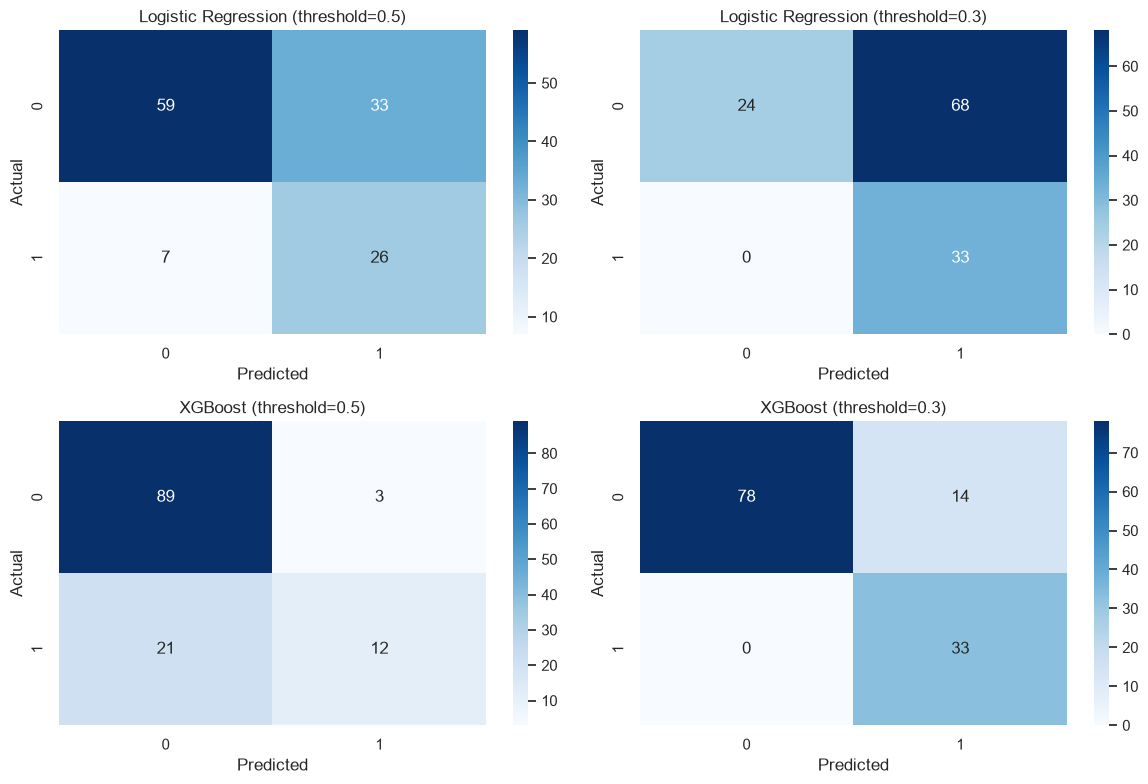

In [84]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

variants = [
    (y_pred_lr, 'Logistic Regression (threshold=0.5)'),
    (y_pred_lr_tuned, 'Logistic Regression (threshold=0.3)'),
    (y_pred_xgb_default, 'XGBoost (threshold=0.5)'),
    (y_pred_xgb, 'XGBoost (threshold=0.3)'),
]

for ax, (preds, title) in zip(axes.flatten(), variants):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax)
    ax.set_title(title)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

## Confusion Matrices Stressed State Model

Each matrix shows how well the model predicts stressed days (1) vs non-stressed days (0).

- **Top left** = correctly predicted not stressed
- **Top right** = predicted stressed but was wrong (false alarm)
- **Bottom left** = missed actual stressed days (dangerous)
- **Bottom right** = correctly predicted stressed

---

### Logistic Regression (threshold=0.5)
- Caught 26 out of 33 stressed days — missed 7
- Made 33 false alarms out of 92 non-stressed days
- Misses 1 in 5 stressed days — not reliable enough for risk management

### Logistic Regression (threshold=0.3)
- Caught all 33 stressed days — missed 0
- But made 68 false alarms — nearly every non-stressed day flagged as stressed
- Perfect recall but practically useless — too many false alarms

### XGBoost (threshold=0.5)
- Caught only 12 out of 33 stressed days — missed 21
- Very few false alarms (only 3)
- Too conservative — misses 64% of stressed days

### XGBoost (threshold=0.3) Best model
- Caught all 33 stressed days — missed 0
- Only 14 false alarms out of 92 non-stressed days
- Perfect recall with manageable false alarms — the best tradeoff


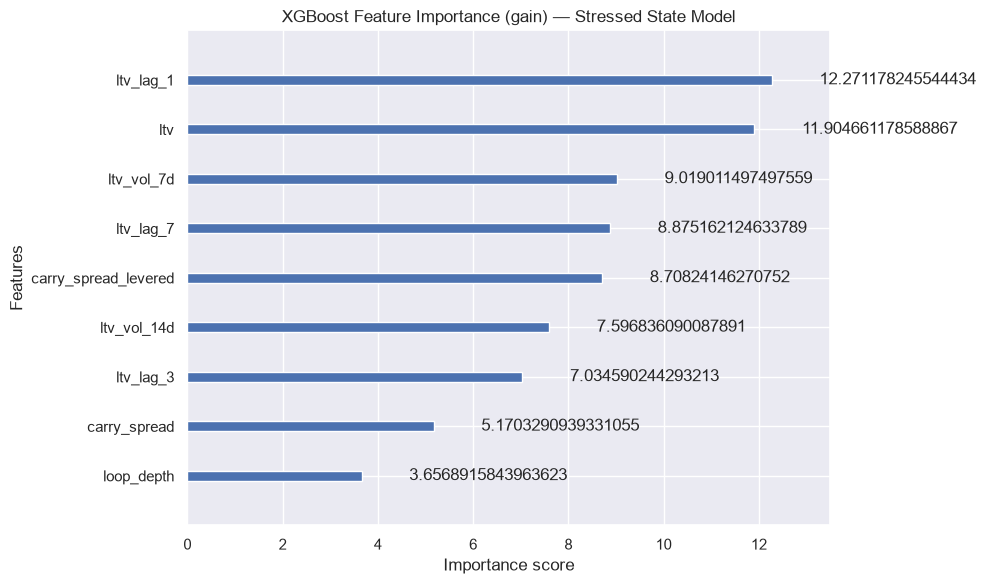

In [85]:
fig, ax = plt.subplots(figsize=(10, 6))
xgb.plot_importance(xgb_model, ax=ax, max_num_features=12, importance_type='gain')
ax.set_title('XGBoost Feature Importance (gain) — Stressed State Model')
plt.tight_layout()
plt.show()

## XGBoost Feature Importance — Stressed State Model

This chart shows which features the model relied on most to predict stressed states.
Higher score = more useful for making predictions.

### Top features:

- **`ltv_lag_1` (12.3)** — yesterday's LTV is the strongest predictor of stress today.
  If leverage was high yesterday it is very likely still high or higher today.
- **`ltv` (11.9)** — current LTV is almost equally important. Stress is an
  instantaneous state — where you are right now matters as much as where you were.
- **`ltv_vol_7d` (9.0)** — volatile leverage over the past week signals stress.
  Unstable positions are more likely to be in a stressed state.
- **`ltv_lag_7` (8.9)** — LTV from 7 days ago still contributes — sustained high
  leverage over a week is a strong stress signal.
- **`carry_spread_levered` (8.7)** — the levered yield spread matters for stress.
  When yield compresses relative to borrow cost, the position becomes less profitable
  and more stressed.

### Bottom features:

- **`carry_spread` (5.2)** — unlevered yield spread has less influence than the
  levered version.
- **`loop_depth` (3.7)** — least important. Strategy intensity alone does not predict
  stress — it is the leverage level that matters, not how many loops were used.

### Key difference from the Rebalancing Model:

| | Rebalancing Model | Stressed State Model |
|---|---|---|
| Top feature | `ltv_lag_7` | `ltv_lag_1` |
| Current `ltv` rank | 8th | 2nd |
| `carry_spread` rank | Last | 5th |

Stressed states are driven by **current and very recent leverage** — it is a present
snapshot. Rebalancing is driven by **leverage buildup over a week** — it is a delayed
response. Yield compression (`carry_spread_levered`) matters for stress but not for
rebalancing — whales rebalance for risk reasons, not yield reasons.

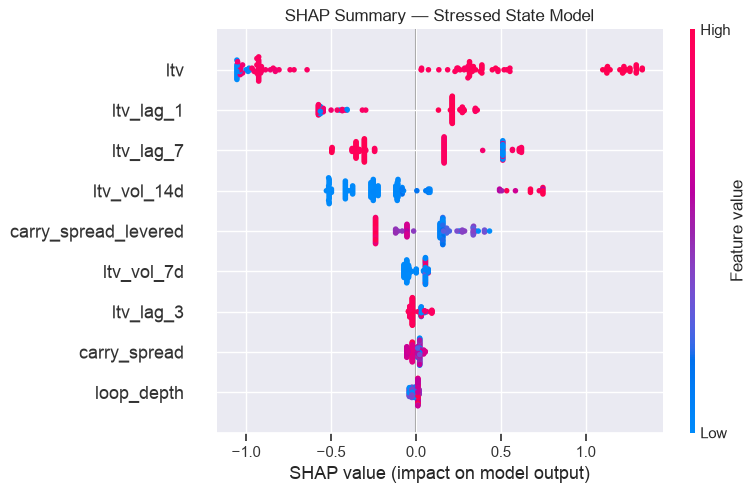

In [86]:
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, feature_names=FEATURES, show=False)
plt.title('SHAP Summary — Stressed State Model')
plt.tight_layout()
plt.show()

## SHAP Summary Stressed State Model

Each dot is one day in the test set. Position on the x-axis shows how much that
feature pushed the prediction toward stressed (right) or away from it (left).
Color shows the feature value — pink = high, blue = low.

### Reading each feature:

**`ltv` — top feature, clearest pattern**
- Pink dots far right → high LTV strongly predicts stressed state
- Blue dots far left → low LTV strongly reduces stress prediction
- The most direct signal — high leverage today means stressed today

**`ltv_lag_1`**
- Pink dots right → high LTV yesterday still predicts stress today
- Slightly weaker than current LTV — stress is present-driven but recent history matters

**`ltv_lag_7`**
- Mixed pattern — both colors on both sides
- 7-day old LTV has a complex relationship with stress
- Sometimes high old LTV predicts stress, sometimes not — depends on what happened since

**`ltv_vol_14d`**
- Blue dots left — low volatility over 14 days reduces stress prediction
- Pink dots right — high volatility pushes toward stress
- Unstable leverage over two weeks is a stress signal

**`carry_spread_levered`**
- Blue dots slightly right — low levered yield spread pushes toward stress
- High spread (pink) slightly reduces stress — when yield is good the position is
  less stressed
- Yield compression is a stress contributor

**`carry_spread`, `loop_depth`, `ltv_vol_7d`, `ltv_lag_3`**
- All clustered near zero — minimal influence on predictions

### Key thesis finding:

Stressed states are driven by **high current LTV** — it is an instantaneous signal.
Unlike the rebalancing model where historical lags dominated, here today's leverage
level is the primary driver. Yield compression (`carry_spread_levered`) has a
secondary protective effect — when levered yield is high the position is less likely
to be stressed.

In [79]:
results = data.loc[X_test.index].copy()
results['pred_stressed'] = y_pred_xgb
results['pred_proba_stressed'] = xgb_model.predict_proba(X_test)[:,1]
results[['whale_id', 'date', 'stressed_state', 'pred_stressed', 'pred_proba_stressed']].to_csv('predictions_stressed.csv', index=False)
print('Saved: predictions_stressed.csv')

Saved: predictions_stressed.csv
